<a href="https://colab.research.google.com/github/PemmakaLakshmiVani/MLA0201-Fundamentals-of-Machine-Learning/blob/main/EXP2_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training Data:
     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High  Strong  Cool   Change        Yes

Specific Boundary S:
['Sunny', 'Warm', '?', 'Strong', '?', '?']

General Boundary G:
['Sunny', '?', '?', '?', '?', '?']
['?', 'Warm', '?', '?', '?', '?']
['?', '?', '?', 'Strong', '?', '?']
['?', '?', '?', '?', 'Warm', '?']
['?', '?', '?', '?', '?', 'Same']


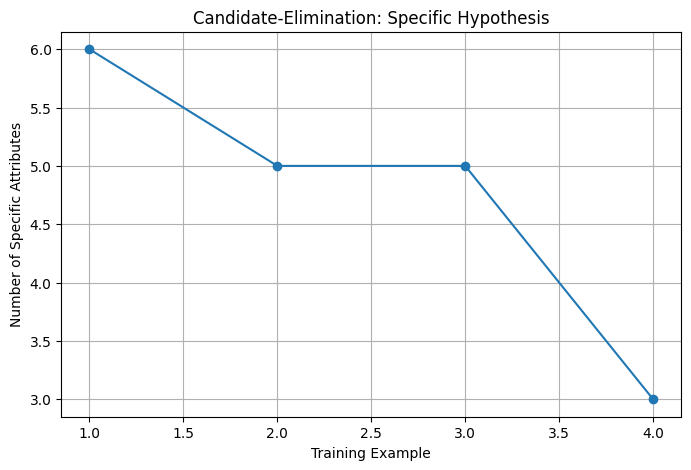

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Training data
data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

# Save data as CSV
df.to_csv('training_data.csv', index=False)

print("Training Data:")
print(df)

attributes = list(df.columns[:-1])

# Initial hypotheses
S = ['0'] * len(attributes)
G = [['?'] * len(attributes)]

S_history = []

# Candidate Elimination
for _, row in df.iterrows():

    if row['EnjoySport'] == 'Yes':

        for i in range(len(attributes)):

            if S[i] == '0':
                S[i] = row[attributes[i]]

            elif S[i] != row[attributes[i]]:
                S[i] = '?'

    else:

        new_G = []

        for g in G:

            for i in range(len(attributes)):

                if g[i] == '?' and S[i] != '?':

                    new_g = g.copy()
                    new_g[i] = S[i]

                    if new_g not in new_G:
                        new_G.append(new_g)

        G = new_G

    S_history.append(sum(1 for x in S if x != '?' and x != '0'))

print("\nSpecific Boundary S:")
print(S)

print("\nGeneral Boundary G:")
for g in G:
    print(g)

# Graph
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(S_history) + 1),
    S_history,
    marker='o'
)

plt.xlabel("Training Example")
plt.ylabel("Number of Specific Attributes")
plt.title("Candidate-Elimination: Specific Hypothesis")
plt.grid(True)

plt.show()